In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import os
import pyabc
import matplotlib.lines as mlines
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec
from scipy.stats import mannwhitneyu, ttest_ind
from scipy.stats import pearsonr

from plotting_tools import * 

In [2]:
plot_path = f"../plots/dual_fits"
os.makedirs(plot_path, exist_ok=True)

In [3]:
db_path = f"../../1_estimation/output/HEV_dual.db"
history = pyabc.History("sqlite:///" + db_path)

In [4]:
obs = pd.read_csv(f"../../0_data/ww.csv", sep=",", index_col=False)

obs = obs.loc[:, ["Sample ID", "Name", "Date", "Comment WW", "HEV per 5 µL", "PMMoV (Cp)"]]

obs = obs.map(lambda v: pd.NA if isinstance(v, str) and '-' in v else v)
obs = obs.replace({"": pd.NA})
obs = obs.replace({"n.d.": 0})

obs = obs.dropna(subset=["PMMoV (Cp)"])
exclude_ids = {"2095","2136","2099","2138","2105","2131","2119","2137","2122","2139","2107","2132","2134","2295"}
obs = obs[~obs["Sample ID"].astype(str).isin(exclude_ids)]

obs.loc[obs["Name"].str.lower() == "schmidbartlanger", "Name"] = "Schmidbartlanger"
obs = obs[obs["Name"].isin(["Schmidbartlanger", "24h Probe"])]

s = obs["Date"].astype(str).str.strip()
obs["Date"] = pd.to_datetime(s, format="%m/%d/%y", errors="coerce")
mask = obs["Date"].isna()
obs.loc[mask, "Date"] = pd.to_datetime(s[mask], format="%m/%d/%Y", errors="coerce")

for col in ["HEV per 5 µL", "PMMoV (Cp)"]:
    obs[col] = pd.to_numeric(obs[col].astype(str).str.replace(",", "", regex=False),errors="coerce")

obs["ConcF"] = np.where(obs["Comment WW"] == "frozen", 38 * 2 / 0.06, 38 / 0.06)
obs["HEV_L"] = obs["HEV per 5 µL"] * 1000 / (0.005 * obs["ConcF"])

obs["PMMoV_1µL"] = 1.972 ** (39.65 - obs["PMMoV (Cp)"])
obs["PMMoV_L"]   = obs["PMMoV_1µL"] * 1000 / (0.001 * obs["ConcF"])

obs["PMMoV_mean"] = np.where(obs["Name"] == "24h Probe", 6_500_000, np.where(obs["Comment WW"] == "fresh", 15_000_000, 8_300_000))
obs["Norm"] = obs["PMMoV_mean"] / obs["PMMoV_L"]

obs["HEV_c"] = obs["HEV_L"] * obs["Norm"]

obs["Category"] = "Non-Emergency"
mask1 = (obs["Date"] >= pd.to_datetime("12/09/2020", format="%m/%d/%Y")) & (obs["Date"] <= pd.to_datetime("06/06/2021", format="%m/%d/%Y"))
mask2 = (obs["Date"] >= pd.to_datetime("11/11/2021", format="%m/%d/%Y")) & (obs["Date"] <= pd.to_datetime("05/11/2022", format="%m/%d/%Y"))
obs.loc[mask1 | mask2, "Category"] = "Emergency"


In [5]:
npz = np.load('../../1_estimation/output/thinned_cases_dual.npz')
obs_sets = {
    'Non-Emergency': npz['obs_sets_nl'],
    'Emergency':     npz['obs_sets_l'],
}

In [6]:
rows = []
for p in range(0, history.max_t + 1):
    particles = history.get_population(p).get_particles_by_model()[0]
    for particle in particles[:200]:
        rows.append({
            "distance": particle.distance,
            "population": (p + 1)
        })

df_dist = pd.DataFrame(rows)

all_pops = history.get_all_populations()
df = all_pops.T
samples = df.loc[df.index == "samples"]
samples = samples.transpose()
samples["population"] = range(0, history.max_t + 2, 1)
samples["Acceptance rate"] = 200 / samples["samples"] * 100 
samples["samples_scaled"] = samples["samples"] / 1e4
samples = samples.drop(0)

In [7]:
samples.tail()

,samples,population,Acceptance rate,samples_scaled
13,3230,13,6.19195,0.323
14,3571,14,5.600672,0.3571
15,6533,15,3.061381,0.6533
16,6869,16,2.911632,0.6869
17,10196,17,1.961554,1.0196


In [8]:
all_pops = pd.concat([all_pops, all_pops["population_end_time"].shift()], axis=1).dropna()
all_pops.columns = ["t", "end_time", "samples", "epsilon", "particles", "start_time"]
all_pops['diff_minutes'] = (all_pops['end_time'] - all_pops['start_time']).dt.total_seconds() / 60
print(all_pops)

     t                   end_time  samples   epsilon  particles  \
1    0 2025-11-18 18:16:26.280797      417  2.714964        200   
2    1 2025-11-18 19:21:07.277559      521  2.323817        200   
3    2 2025-11-18 20:31:53.424322      571  2.090874        200   
4    3 2025-11-18 21:51:06.350542      632  1.910646        200   
5    4 2025-11-18 23:33:49.586795      823  1.707010        200   
6    5 2025-11-19 01:15:42.980768      818  1.576932        200   
7    6 2025-11-19 02:59:00.379104      831  1.477679        200   
8    7 2025-11-19 05:26:13.582521     1196  1.347368        200   
9    8 2025-11-19 08:34:18.033578     1528  1.258188        200   
10   9 2025-11-19 11:35:49.118591     1471  1.186746        200   
11  10 2025-11-19 16:15:25.037659     2274  1.118517        200   
12  11 2025-11-19 20:52:05.955686     2250  1.070448        200   
13  12 2025-11-20 03:28:54.931312     3230  1.015119        200   
14  13 2025-11-20 10:47:33.963804     3571  0.970855        20

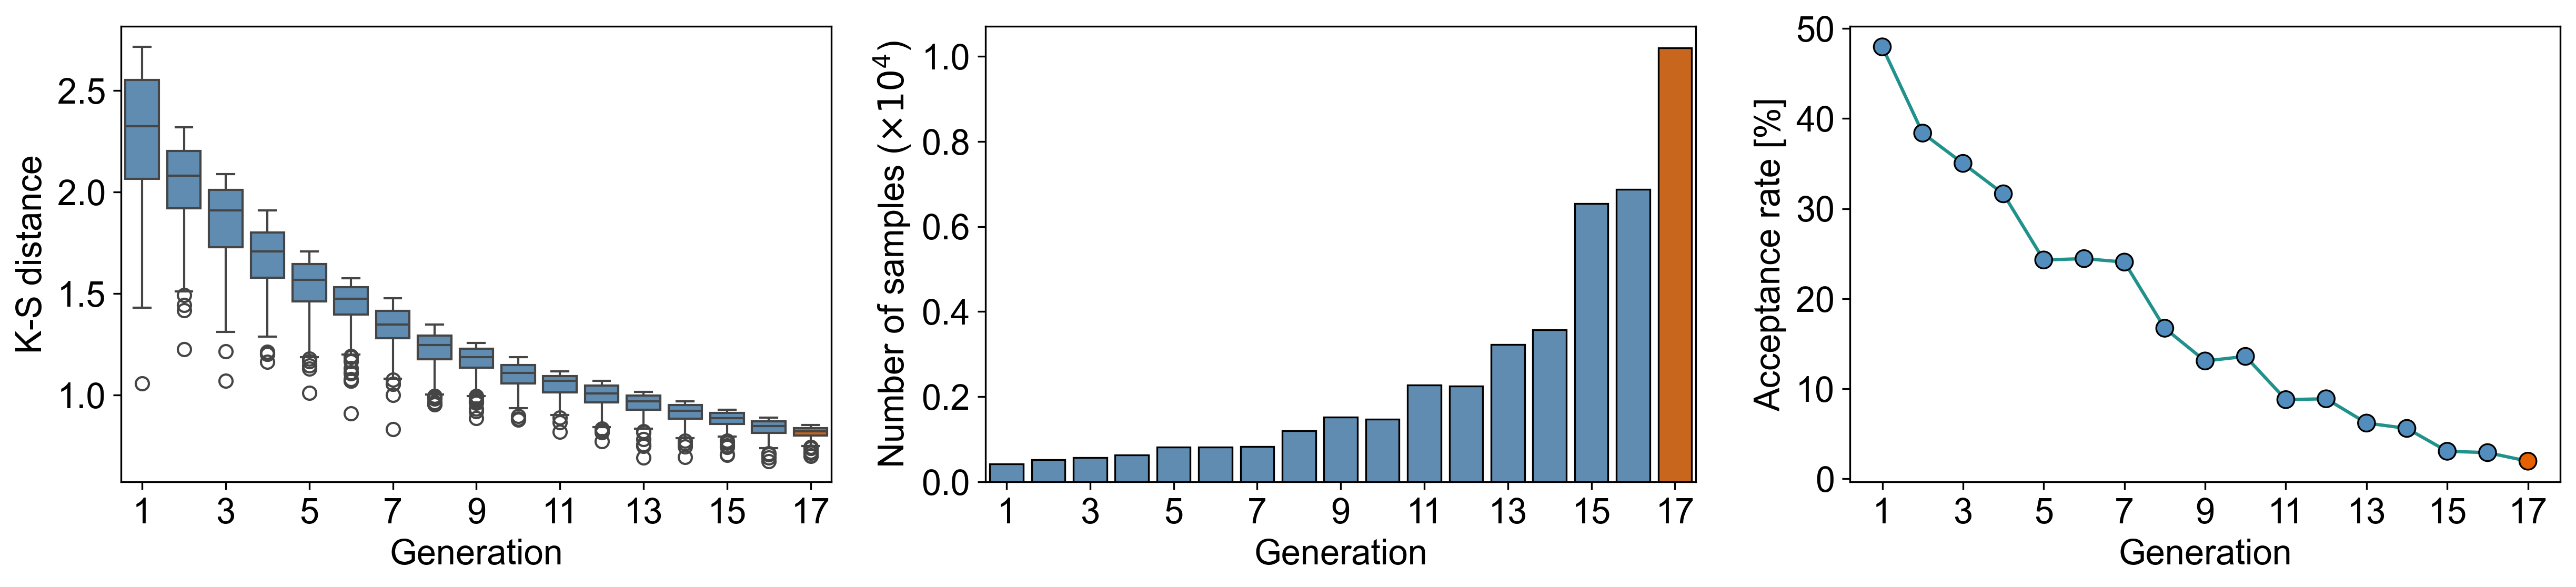

In [9]:
plt.style.use('default')
set_fontsize()

fig, axes = plt.subplots(figsize = (16.6,4), nrows=1, ncols=3, dpi=300)

unique_pops = sorted(df_dist["population"].unique())
palette = {pop: (orange if pop == 17 else lightblue) for pop in unique_pops}

sns.boxplot(data = df_dist, x = "population", y = "distance", hue = "population", legend = False, palette = palette, ax = axes[0])
axes[0].set_ylabel("K-S distance")
axes[0].set_xlabel("Generation")
axes[0].set_xticks(range(0, len(unique_pops), 2))

sns.barplot(data = samples, x = 'population', y = 'samples_scaled', hue = "population", legend = False, palette = palette, ax = axes[1])
for patch in axes[1].patches:
    patch.set_edgecolor('black')
    patch.set_linewidth(0.8)
axes[1].set_ylabel(r"Number of samples ($\times 10^{4}$)")
axes[1].set_xlabel("Generation")
axes[1].set_xticks(range(0, len(unique_pops), 2))
#axes[1].ticklabel_format(style='sci', axis='y', scilimits=(0, 0))

means = (samples.groupby('population', as_index=False)['Acceptance rate'].mean().sort_values('population'))
axes[2].plot(means['population'], means['Acceptance rate'], linewidth=1.5, c = teal, zorder=1)
sns.scatterplot(data=samples, x='population', y='Acceptance rate', hue = "population", legend = False, ax = axes[2], palette = palette, marker='o', edgecolor='black', linewidth=0.8, s=60, zorder=2)
axes[2].set_xlabel("Generation")
axes[2].set_xticks(range(1, len(unique_pops) + 1, 2))
axes[2].set_ylabel("Acceptance rate [%]")

plt.tight_layout()
plt.savefig(f"{plot_path}/generations.png", dpi=300)
plt.show()

In [10]:
p = history.max_t

rows = []
particles = history.get_population(p).get_particles_by_model()[0]
for particle_id, particle in enumerate(particles[:200]):
    for d in np.atleast_1d(particle.sum_stat["GG_nl"]):
        rows.append({
            "ww": d,
            "particle": particle_id + 1,
            "population": (p + 1)
        })
sim_GG_nl = pd.DataFrame(rows)
sim_GG_nl["Name"] = "24h Probe"
sim_GG_nl["Category"] = "Non-Emergency"

rows = []
particles = history.get_population(p).get_particles_by_model()[0]
for particle_id, particle in enumerate(particles[:200]):
    for d in np.atleast_1d(particle.sum_stat["GG_l"]):
        rows.append({
            "ww": d,
            "particle": particle_id + 1,
            "population": (p + 1)
        })
sim_GG_l = pd.DataFrame(rows)
sim_GG_l["Name"] = "24h Probe"
sim_GG_l["Category"] = "Emergency"

rows = []
particles = history.get_population(p).get_particles_by_model()[0]
for particle_id, particle in enumerate(particles[:200]):
    for d in np.atleast_1d(particle.sum_stat["S_nl"]):
        rows.append({
            "ww": d,
            "particle": particle_id + 1,
            "population": (p + 1)
        })
sim_S_nl = pd.DataFrame(rows)
sim_S_nl["Name"] = "Schmidbartlanger"
sim_S_nl["Category"] = "Non-Emergency"

rows = []
particles = history.get_population(p).get_particles_by_model()[0]
for particle_id, particle in enumerate(particles[:200]):
    for d in np.atleast_1d(particle.sum_stat["S_l"]):
        rows.append({
            "ww": d,
            "particle": particle_id + 1,
            "population": (p + 1)
        })
sim_S_l = pd.DataFrame(rows)
sim_S_l["Name"] = "Schmidbartlanger"
sim_S_l["Category"] = "Emergency"

sim_ww = pd.concat([sim_GG_nl, sim_GG_l, sim_S_nl, sim_S_l], ignore_index=True)
sim_ww["ww_scaled"] = sim_ww["ww"] / 1e5

In [11]:
rows = []
particles = history.get_population(p).get_particles_by_model()[0]
for particle_id, particle in enumerate(particles[:200]):
    for d in np.atleast_1d(particle.sum_stat["cases_nl"]):
        rows.append({
            "cases": d,
            "particle": particle_id + 1,
            "population": (p + 1)
        })
sim_nl = pd.DataFrame(rows)
sim_nl["Category"] = "Non-Emergency"

rows = []
particles = history.get_population(p).get_particles_by_model()[0]
for particle_id, particle in enumerate(particles[:200]):
    for d in np.atleast_1d(particle.sum_stat["cases_l"]):
        rows.append({
            "cases": d,
            "particle": particle_id + 1,
            "population": (p + 1)
        })
sim_l = pd.DataFrame(rows)
sim_l["Category"] = "Emergency"

sim_cases = pd.concat([sim_l, sim_nl], ignore_index=True)

In [12]:
def compute_ecdf_band(df, x_grid, x_max):
    particle_ecdfs = []
    for pid, group in df.groupby("particle"):
        x = np.sort(group["ww_scaled"])
        y = np.arange(1, len(x) + 1) / len(x)
        x = np.append(x, x_max)
        y = np.append(y, 1.0)
        y_interp = np.interp(x_grid, x, y)
        particle_ecdfs.append(y_interp)

    particle_ecdfs = np.vstack(particle_ecdfs)
    lower = np.percentile(particle_ecdfs, 2.5, axis=0)
    mean = np.mean(particle_ecdfs, axis=0)
    upper = np.percentile(particle_ecdfs, 97.5, axis=0)
    return lower, mean, upper

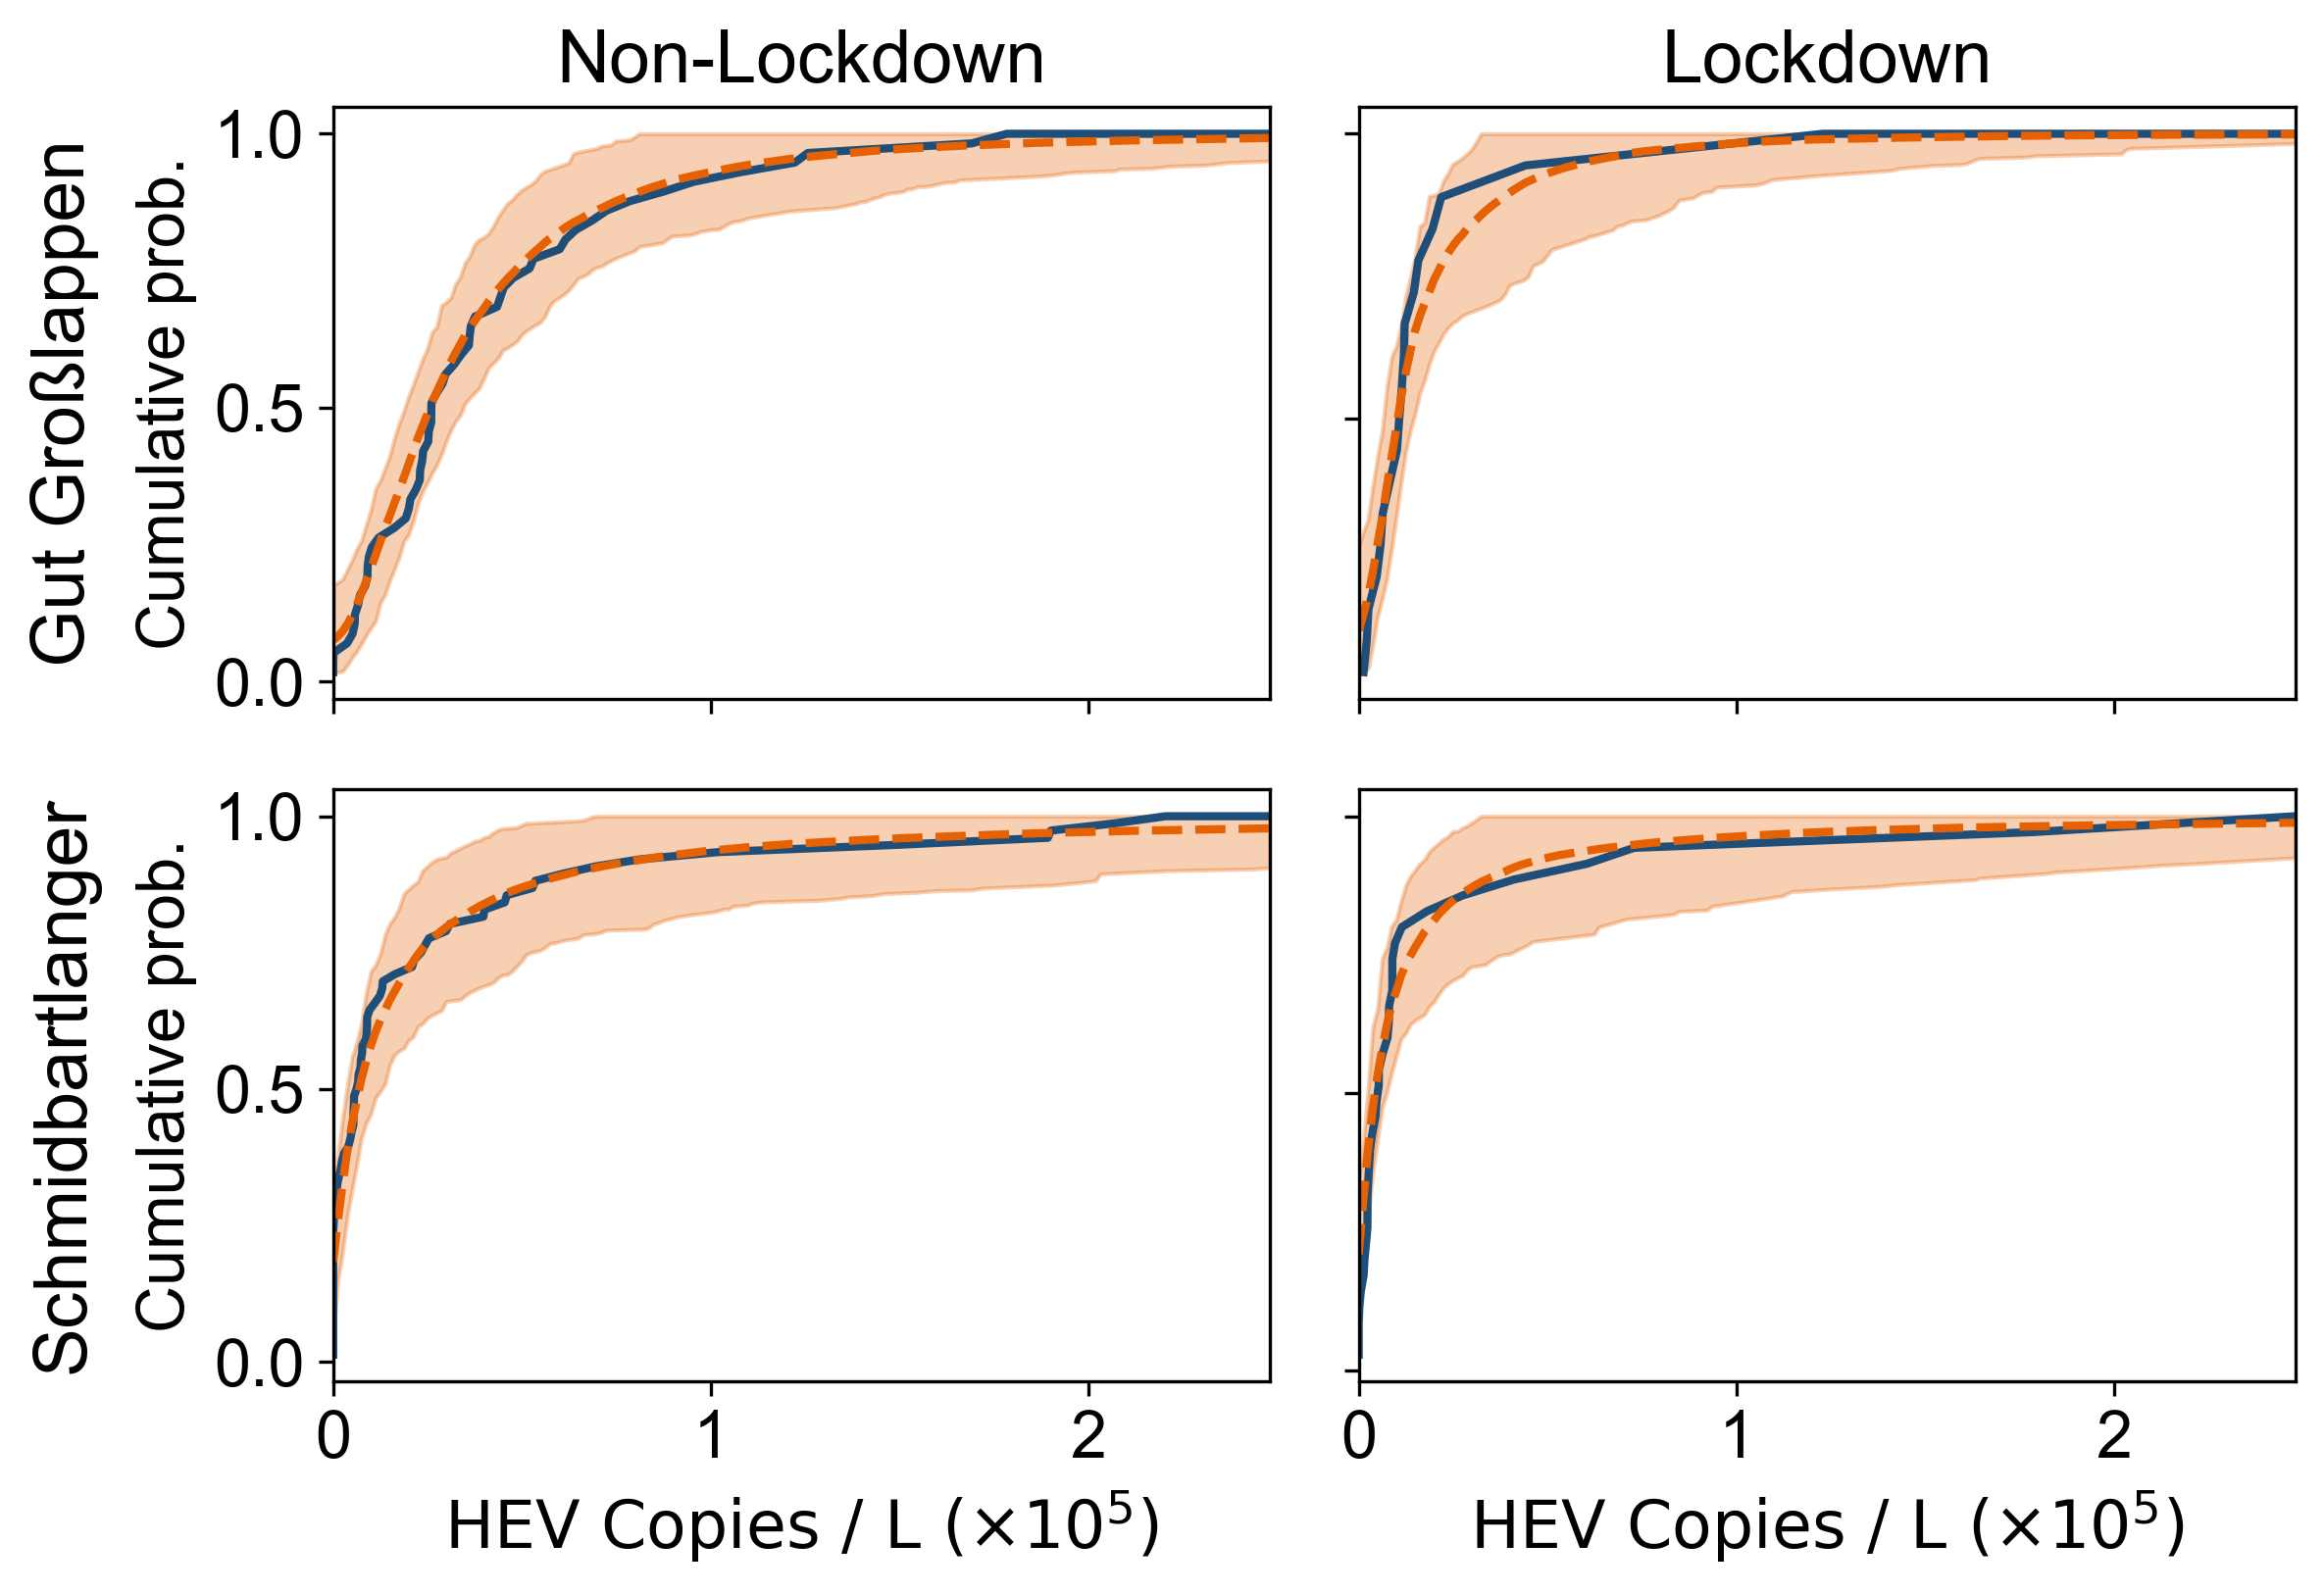

In [13]:
plt.style.use('default')
set_fontsize()

locs = ['24h Probe', 'Schmidbartlanger']
categories = ['Non-Emergency', 'Emergency']
x_min, x_max = obs['HEV_c'].min() / 1e5, obs['HEV_c'].max() / 1e5
x_grid = np.linspace(x_min, x_max, 200)

fig, axes = plt.subplots(figsize = (8.1,5.7), nrows=2, ncols=2, dpi=300)

for i, name in enumerate(locs):
    for j, cat in enumerate(categories):
        ax = axes[i, j]

        subset = obs[(obs['Name'] == name) & (obs['Category'] == cat)].copy()
        subset["HEV_c"] = subset["HEV_c"] / 1e5
        x = np.sort(subset['HEV_c'])
        y = np.arange(1, len(x) + 1) / len(x)
        x = np.append(x, x_max)
        y = np.append(y, 1.0)
        ax.plot(x, y, color=darkblue, linewidth=2, label="Empirical data")
        #mean_emp = subset["HEV_c"].median()
        #ax.axvline(mean_emp, color=darkblue, linestyle=":", linewidth=1.2, label=None)

        sim_sub = sim_ww[(sim_ww["Name"] == name) & (sim_ww["Category"] == cat)]
        if not sim_sub.empty:
            lower, mean, upper = compute_ecdf_band(sim_sub, x_grid, x_max)
            ax.fill_between(x_grid, lower, upper, color=orange, alpha=0.3, label="Sim. result (gen. 19) – 95% SI")
            ax.plot(x_grid, mean, color=orange, linewidth=2, linestyle='--', label="Sim. result (gen. 19) – mean")
            #mean_sim = sim_sub.groupby("particle")["ww_scaled"].median().median()
            #ax.axvline(mean_sim, color=orange, linestyle=":", linewidth=1.2, label=None)

            #text_str = "\n".join([rf"Emp. med. = ${mean_emp*10:.1f} \times 10^{4}$", rf"Sim. med. = ${mean_sim*10:.1f} \times 10^{4}$"])
            #ax.text(0.97, 0.05, text_str, transform=ax.transAxes, ha='right', va='bottom', fontsize=16, bbox=dict(boxstyle="round", facecolor="white", alpha=0.8, edgecolor="none"))

        ax.set_title("")

        if i == 0:
            ax.set_xlabel("")
            ax.set_xticklabels([])
            ax.tick_params(axis='x', which='both', bottom=True, top=False, labelbottom=False)
        else:
            ax.set_xlabel(r"$\mathrm{HEV\ Copies\ / \ L\ ( \times 10^{5})}$")
            ax.ticklabel_format(axis='x', style='plain')

        if j == 1:
            ax.set_ylabel("")
            ax.set_yticklabels([])
            ax.tick_params(axis='y', which='both', left=True, right=False, labelleft=False)
        else:
            ax.set_ylabel("Cumulative prob.")

        ax.set_xlim(x_min, x_max)

display_names = {'24h Probe': 'Gut Großlappen', 'Schmidbartlanger': 'Schmidbartlanger', 'Emergency': 'Lockdown', 'Non-Emergency': 'Non-Lockdown'}

for j, cat in enumerate(categories):
    axes[0, j].set_title(display_names.get(cat, cat))

for i, name in enumerate(locs):
    axes[i, 0].annotate(
        display_names.get(name, name),
        xy=(-0.25, 0.5),
        xycoords='axes fraction',
        ha='right',
        va='center',
        rotation=90,
        fontsize=18
    )

# handles, labels = axes[0,0].get_legend_handles_labels()
# order = [2, 1, 0] 
# handles = [handles[i] for i in order]
# labels = [labels[i] for i in order]
# 
# fig.legend(
#     handles, labels,
#     loc='lower center',
#     ncol=2,           
#     frameon=True,
#     bbox_to_anchor=(0.5, -0.1) 
# )

plt.tight_layout()
plt.savefig(f"{plot_path}/dist-fits.png", dpi=300)
plt.show()

In [14]:
min_count = 0
max_count = 8

def hist_mean_and_interval(obs_set, min_count, max_count, lo_q=2.5, hi_q=97.5):
    means, lo, hi = [], [], []
    for k in range(min_count, max_count + 1):
        freq = np.sum(obs_set == k, axis=1) / obs_set.shape[1]
        means.append(np.mean(freq))
        lo.append(np.percentile(freq, lo_q))
        hi.append(np.percentile(freq, hi_q))
    return means, lo, hi

emp_mean, emp_lo, emp_hi = {}, {}, {}

for k in ['Non-Emergency', 'Emergency']:
    m, lo, hi = hist_mean_and_interval(obs_sets[k], min_count, max_count)
    emp_mean[k], emp_lo[k], emp_hi[k] = m, lo, hi

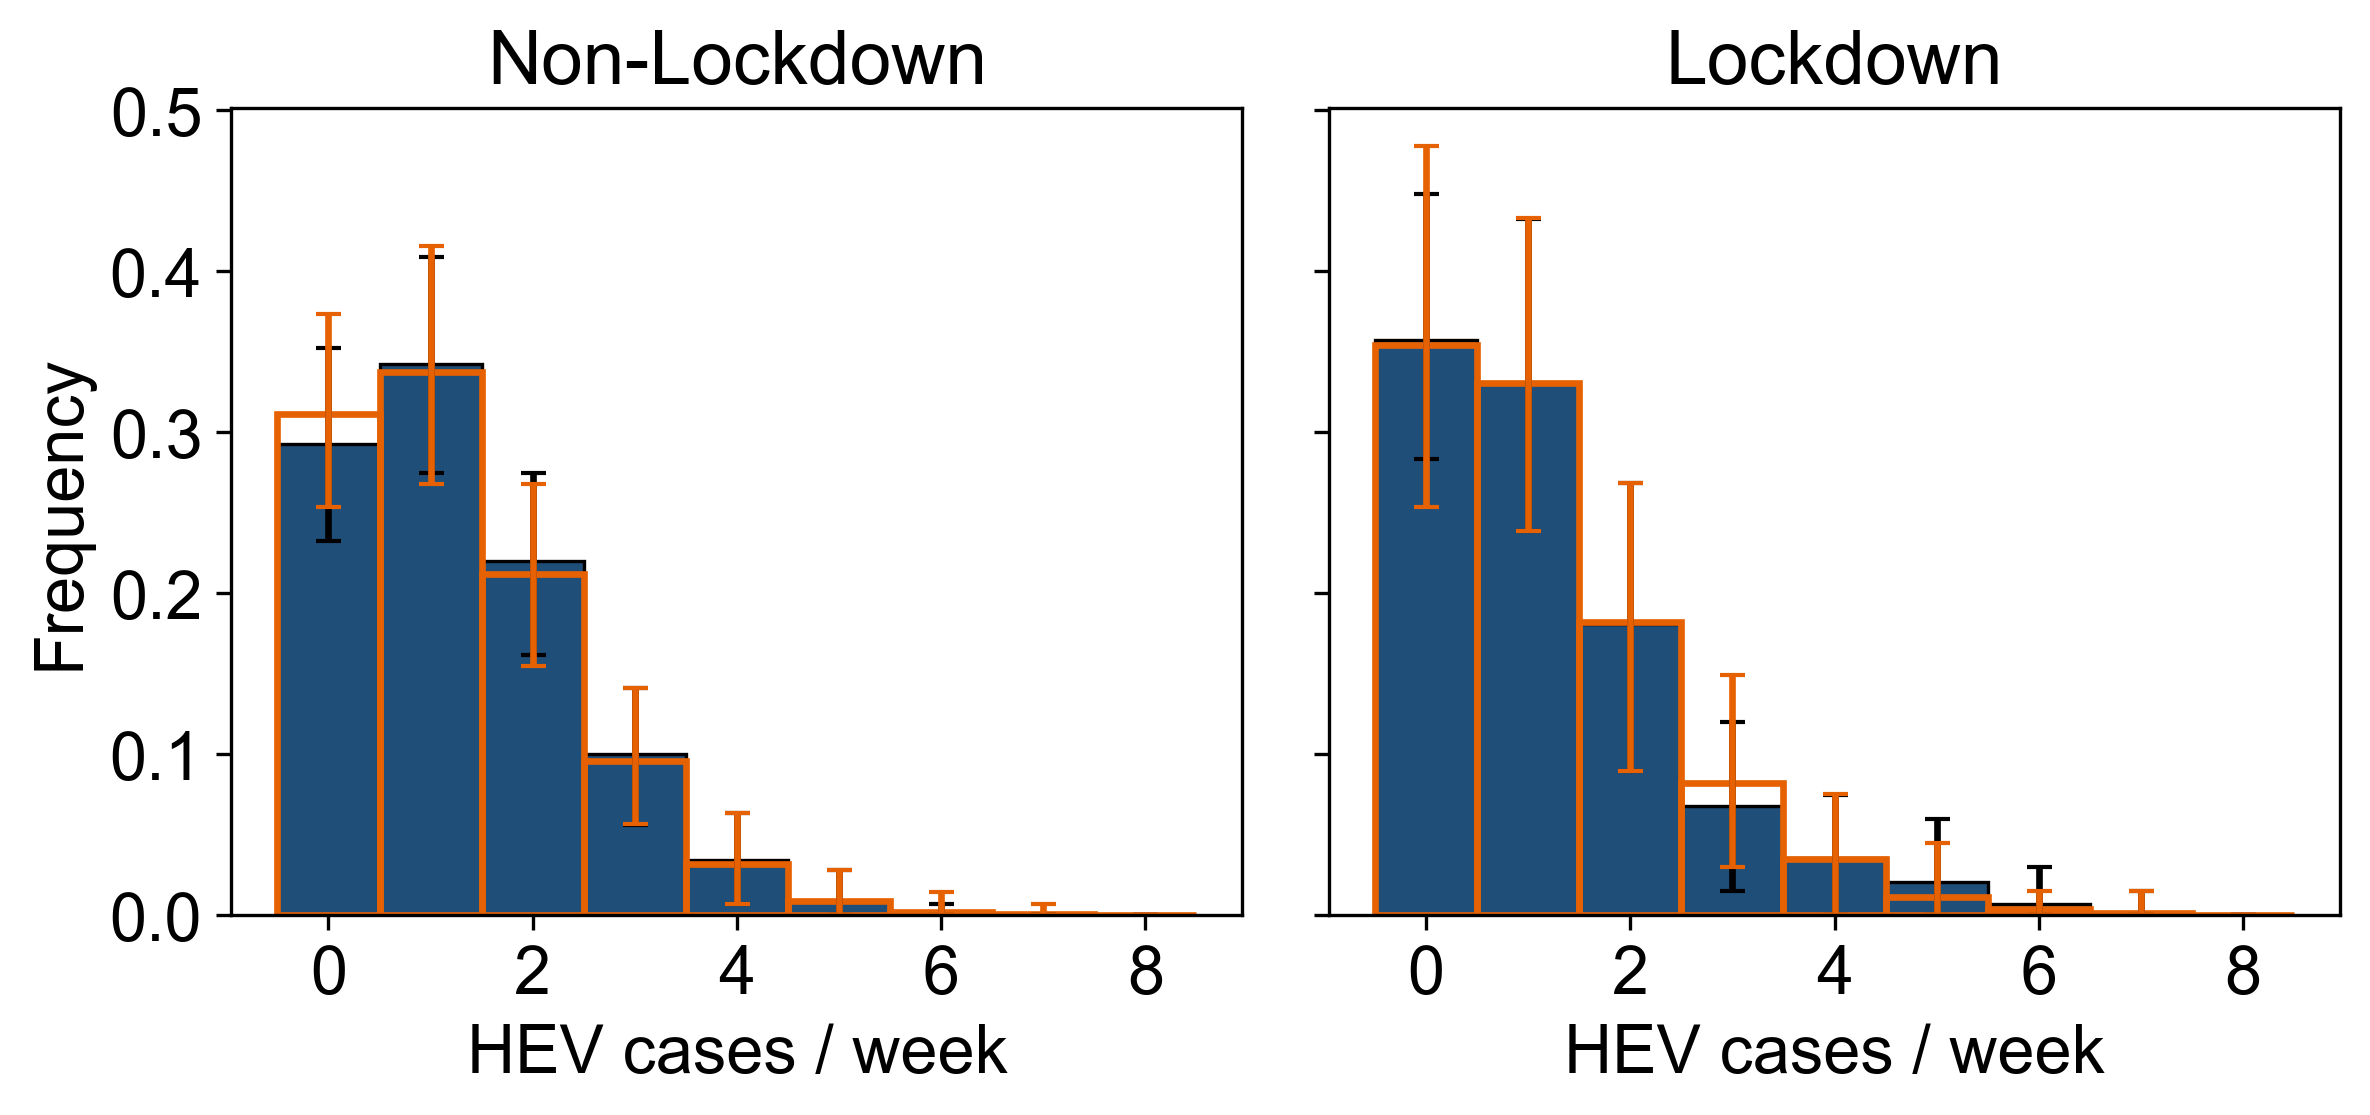

In [15]:
plt.style.use('default')
set_fontsize()

fig, axes = plt.subplots(figsize = (8.18,4), nrows=1, ncols=2, dpi=300, sharex=True, sharey=True)

counts = np.arange(min_count, max_count + 1)
display_names = {'Emergency': 'Lockdown', 'Non-Emergency': 'Non-Lockdown'}

for ax, cat in zip(axes, ['Non-Emergency', 'Emergency']):
    barw = 1
    
    m, lo, hi  = np.asarray(emp_mean[cat]), np.asarray(emp_lo[cat]), np.asarray(emp_hi[cat])
    ax.bar(counts, m, width=barw, color=darkblue, edgecolor='black', linewidth=0.8, label='Empirical data – mean')
    lower_err = np.maximum(0, m - lo)
    upper_err = np.maximum(0, hi - m)
    yerr_emp  = np.vstack([lower_err, upper_err])
    ax.errorbar(counts, m, yerr=yerr_emp, fmt='none', ecolor=medium_grey, elinewidth=1.6, capsize=5, label='Empirical data – 95% SI')

    ssub = sim_cases[sim_cases['Category'] == cat]
    sim_mat = (ssub.groupby(['particle', 'cases']).size().unstack(fill_value=0).reindex(columns=counts, fill_value=0).to_numpy())
    sim_mat = sim_mat / sim_mat.sum(axis=1, keepdims=True)
    sim_mean = sim_mat.mean(axis=0)
    sim_lo = np.percentile(sim_mat, 2.5, axis=0)
    sim_hi = np.percentile(sim_mat, 97.5, axis=0)
    lower_err = np.maximum(0, sim_mean - sim_lo)
    upper_err = np.maximum(0, sim_hi - sim_mean)
    yerr = np.vstack([lower_err, upper_err])
    ax.bar(counts, sim_mean, width=barw, facecolor='none', edgecolor=orange, linewidth=1.6, label="Sim. result (gen. 8) – mean")
    ax.errorbar(counts, sim_mean, yerr=yerr, fmt='none', ecolor=orange, elinewidth=1.6, capsize=3, label="Sim. result (gen. 8) – 95% SI")

    ax.set_title(display_names.get(cat, cat))
    ax.set_xlabel("HEV cases / week")
    ax.set_ylabel("")
    ax.set_xticks([0, 2, 4, 6, 8])

axes[0].set_ylabel("Frequency")
# handles, labels = axes[0].get_legend_handles_labels()
# order = [2, 1, 0]
# handles = [handles[i] for i in order]
# labels = [labels[i] for i in order]
# 
# fig.legend(handles, labels, loc='lower center', ncol=2, frameon=True, bbox_to_anchor=(0.5, -0.1))

plt.tight_layout()
plt.savefig(f"{plot_path}/dist-fits-2.png", dpi=300)
plt.show()

In [23]:
def posterior_to_plot_1d(pop_num, x_var, x_min, x_max, num_x):
    df, w = history.get_distribution(0, pop_num)
    post = pyabc.visualization.kde.kde_1d(df, w, x = x_var, xmin = x_min, xmax = x_max, numx = num_x)
    post_list = list(map(list, zip(*list(post))))
    return pd.DataFrame(post_list, columns = ["x", "prob"])

In [24]:
pop0_ld = posterior_to_plot_1d(pop_num = 0, x_var = "ld", x_min = 0, x_max = 2, num_x = 2001)
pop5_ld = posterior_to_plot_1d(pop_num = 5, x_var = "ld", x_min = 0, x_max = 2, num_x = 2001)
pop10_ld = posterior_to_plot_1d(pop_num = 10, x_var = "ld", x_min = 0, x_max = 2, num_x = 2001)
pop14_ld = posterior_to_plot_1d(pop_num = 14, x_var = "ld", x_min = 0, x_max = 2, num_x = 2001)
pop15_ld = posterior_to_plot_1d(pop_num = 15, x_var = "ld", x_min = 0, x_max = 2, num_x = 2001)
pop16_ld = posterior_to_plot_1d(pop_num = 16, x_var = "ld", x_min = 0, x_max = 2, num_x = 2001)

pop0_ldr = posterior_to_plot_1d(pop_num = 0, x_var = "ldr", x_min = 0, x_max = 10, num_x = 1001)
pop5_ldr = posterior_to_plot_1d(pop_num = 5, x_var = "ldr", x_min = 0, x_max = 10, num_x = 1001)
pop10_ldr = posterior_to_plot_1d(pop_num = 10, x_var = "ldr", x_min = 0, x_max = 10, num_x = 1001)
pop14_ldr = posterior_to_plot_1d(pop_num = 14, x_var = "ldr", x_min = 0, x_max = 10, num_x = 1001)
pop15_ldr = posterior_to_plot_1d(pop_num = 15, x_var = "ldr", x_min = 0, x_max = 10, num_x = 1001)
pop16_ldr = posterior_to_plot_1d(pop_num = 16, x_var = "ldr", x_min = 0, x_max = 10, num_x = 1001)

pop0_scaleG = posterior_to_plot_1d(pop_num = 0, x_var = "scaleG", x_min = 0, x_max = 90000000, num_x = 9001)
pop5_scaleG = posterior_to_plot_1d(pop_num = 5, x_var = "scaleG", x_min = 0, x_max = 90000000, num_x = 9001)
pop10_scaleG = posterior_to_plot_1d(pop_num = 10, x_var = "scaleG", x_min = 0, x_max = 90000000, num_x = 9001)
pop14_scaleG = posterior_to_plot_1d(pop_num = 14, x_var = "scaleG", x_min = 0, x_max = 90000000, num_x = 9001)
pop15_scaleG = posterior_to_plot_1d(pop_num = 15, x_var = "scaleG", x_min = 0, x_max = 90000000, num_x = 9001)
pop16_scaleG = posterior_to_plot_1d(pop_num = 16, x_var = "scaleG", x_min = 0, x_max = 90000000, num_x = 9001)

pop0_scaleS = posterior_to_plot_1d(pop_num = 0, x_var = "scaleS", x_min = 0, x_max = 90000000, num_x = 9001)
pop5_scaleS = posterior_to_plot_1d(pop_num = 5, x_var = "scaleS", x_min = 0, x_max = 90000000, num_x = 9001)
pop10_scaleS = posterior_to_plot_1d(pop_num = 10, x_var = "scaleS", x_min = 0, x_max = 90000000, num_x = 9001)
pop14_scaleS = posterior_to_plot_1d(pop_num = 14, x_var = "scaleS", x_min = 0, x_max = 90000000, num_x = 9001)
pop15_scaleS = posterior_to_plot_1d(pop_num = 15, x_var = "scaleS", x_min = 0, x_max = 90000000, num_x = 9001)
pop16_scaleS = posterior_to_plot_1d(pop_num = 16, x_var = "scaleS", x_min = 0, x_max = 90000000, num_x = 9001)

pop0_noise1G = posterior_to_plot_1d(pop_num = 0, x_var = "noise1G", x_min = 0, x_max = 5, num_x = 5001)
pop5_noise1G = posterior_to_plot_1d(pop_num = 5, x_var = "noise1G", x_min = 0, x_max = 5, num_x = 5001)
pop10_noise1G = posterior_to_plot_1d(pop_num = 10, x_var = "noise1G", x_min = 0, x_max = 5, num_x = 5001)
pop14_noise1G = posterior_to_plot_1d(pop_num = 14, x_var = "noise1G", x_min = 0, x_max = 5, num_x = 5001)
pop15_noise1G = posterior_to_plot_1d(pop_num = 15, x_var = "noise1G", x_min = 0, x_max = 5, num_x = 5001)
pop16_noise1G = posterior_to_plot_1d(pop_num = 16, x_var = "noise1G", x_min = 0, x_max = 5, num_x = 5001)

pop0_noise1S = posterior_to_plot_1d(pop_num = 0, x_var = "noise1S", x_min = 0, x_max = 5, num_x = 5001)
pop5_noise1S = posterior_to_plot_1d(pop_num = 5, x_var = "noise1S", x_min = 0, x_max = 5, num_x = 5001)
pop10_noise1S = posterior_to_plot_1d(pop_num = 10, x_var = "noise1S", x_min = 0, x_max = 5, num_x = 5001)
pop14_noise1S = posterior_to_plot_1d(pop_num = 14, x_var = "noise1S", x_min = 0, x_max = 5, num_x = 5001)
pop15_noise1S = posterior_to_plot_1d(pop_num = 15, x_var = "noise1S", x_min = 0, x_max = 5, num_x = 5001)
pop16_noise1S = posterior_to_plot_1d(pop_num = 16, x_var = "noise1S", x_min = 0, x_max = 5, num_x = 5001)

pop0_noise2G = posterior_to_plot_1d(pop_num = 0, x_var = "noise2G", x_min = 0, x_max = 200, num_x = 2001)
pop5_noise2G = posterior_to_plot_1d(pop_num = 5, x_var = "noise2G", x_min = 0, x_max = 200, num_x = 2001)
pop10_noise2G = posterior_to_plot_1d(pop_num = 10, x_var = "noise2G", x_min = 0, x_max = 200, num_x = 2001)
pop14_noise2G = posterior_to_plot_1d(pop_num = 14, x_var = "noise2G", x_min = 0, x_max = 200, num_x = 2001)
pop15_noise2G = posterior_to_plot_1d(pop_num = 15, x_var = "noise2G", x_min = 0, x_max = 200, num_x = 2001)
pop16_noise2G = posterior_to_plot_1d(pop_num = 16, x_var = "noise2G", x_min = 0, x_max = 200, num_x = 2001)

pop0_noise2S = posterior_to_plot_1d(pop_num = 0, x_var = "noise2S", x_min = 0, x_max = 200, num_x = 2001)
pop5_noise2S = posterior_to_plot_1d(pop_num = 5, x_var = "noise2S", x_min = 0, x_max = 200, num_x = 2001)
pop10_noise2S = posterior_to_plot_1d(pop_num = 10, x_var = "noise2S", x_min = 0, x_max = 200, num_x = 2001)
pop14_noise2S = posterior_to_plot_1d(pop_num = 14, x_var = "noise2S", x_min = 0, x_max = 200, num_x = 2001)
pop15_noise2S = posterior_to_plot_1d(pop_num = 15, x_var = "noise2S", x_min = 0, x_max = 200, num_x = 2001)
pop16_noise2S = posterior_to_plot_1d(pop_num = 16, x_var = "noise2S", x_min = 0, x_max = 200, num_x = 2001)

In [25]:
def plot_group(ax, dfs, xticks=None, xticklabels=None):
    set_fontsize()
    colors = [lightest_grey, lightgrey, medium_grey, darkgrey, darkest_grey, orange]
    for d, c in zip(dfs, colors):
        sns.lineplot(data=d, x="x", y="prob", color=c, ax=ax)

    max_y = max(df['prob'].max() for df in dfs) * 1.05
    min_y = min(df['prob'].min() for df in dfs)

    ax.set(ylim=(min_y, max_y))
    ax.set_yticks([min_y, (min_y + max_y) / 2, max_y])
    ax.set(xlabel=None, ylabel=None, yticklabels=[])

    if xticks is not None:
        ax.set_xticks(xticks)
    if xticklabels is not None:
        ax.set_xticklabels(xticklabels)

    for spine in ax.spines.values():
        spine.set_visible(True)
    ax.margins(x=0, y=0)

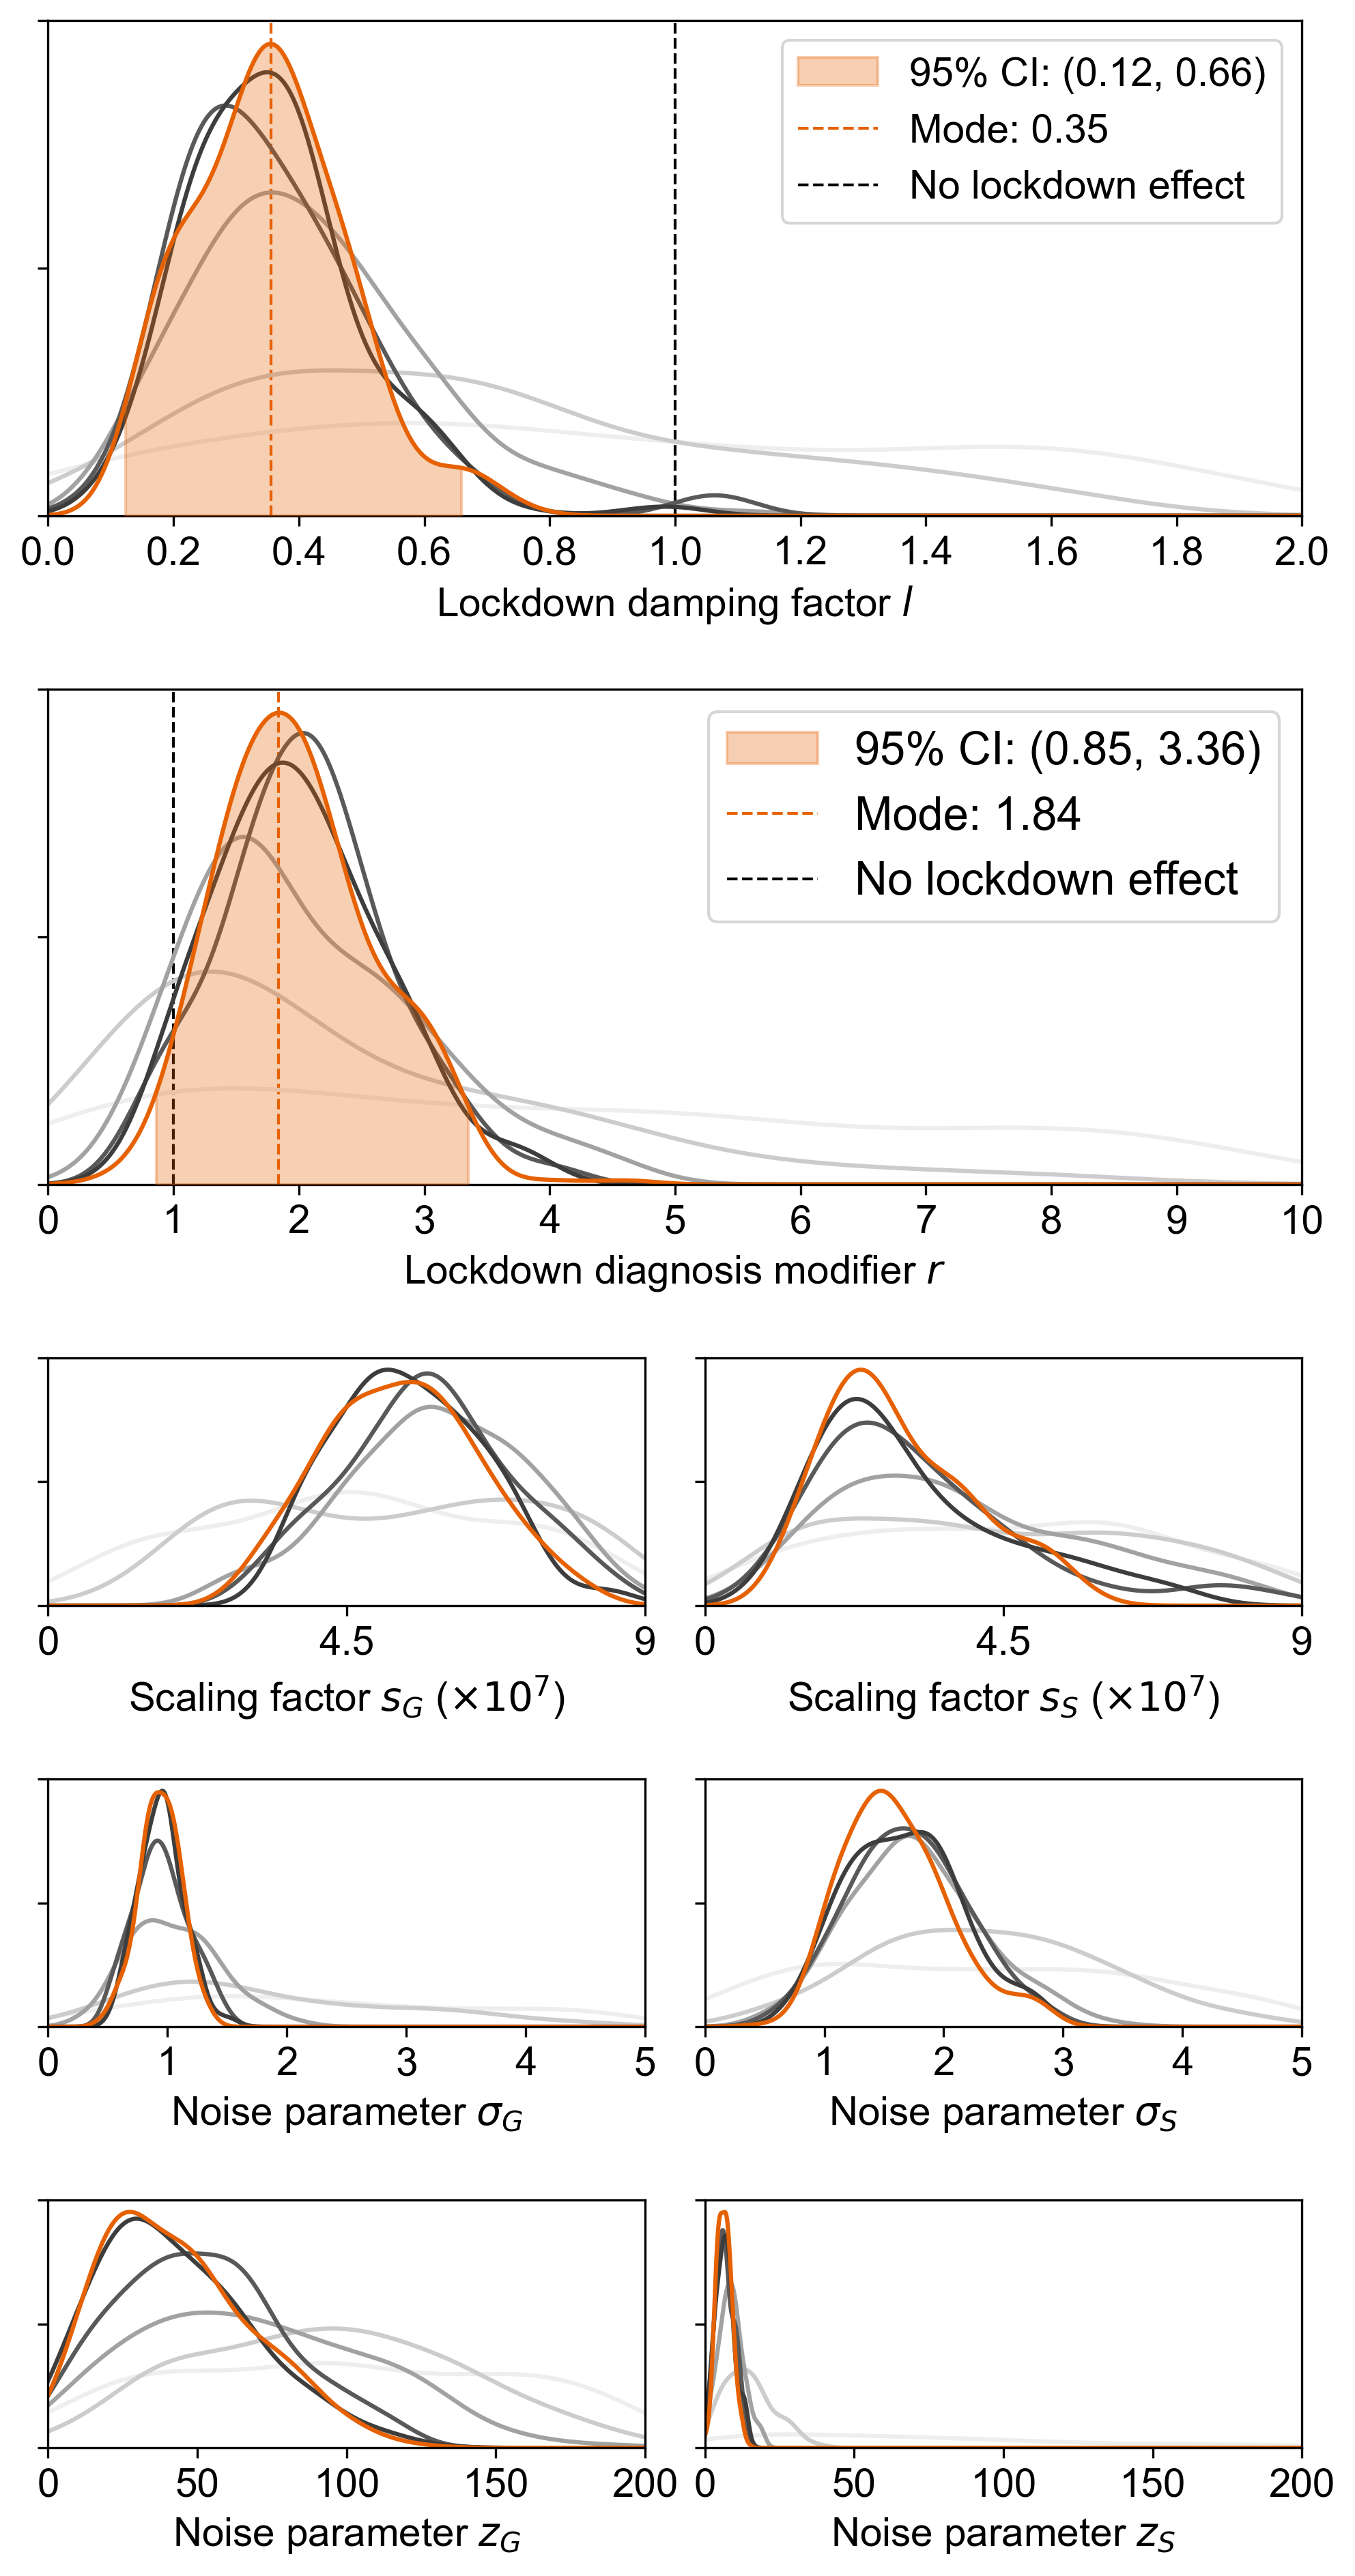

In [26]:
plt.style.use('default')
set_fontsize(14)

fig = plt.figure(figsize=(7.9, 15.4), dpi=300)
gs = GridSpec(nrows=5, ncols=2, figure=fig, hspace=0.5, wspace=0.1, height_ratios=[2, 2, 1, 1, 1])

ax_ld = fig.add_subplot(gs[0, :])
ax_ldr = fig.add_subplot(gs[1, :])
ax_scaleG   = fig.add_subplot(gs[2, 0])
ax_scaleS   = fig.add_subplot(gs[2, 1])
ax_noise1G  = fig.add_subplot(gs[3, 0])
ax_noise1S  = fig.add_subplot(gs[3, 1])
ax_noise2G  = fig.add_subplot(gs[4, 0])
ax_noise2S  = fig.add_subplot(gs[4, 1])

x = pop16_ld['x'].to_numpy()
y = pop16_ld['prob'].to_numpy()
x_mode = x[np.argmax(y)]
cdf = np.cumsum(y)
cdf = cdf / cdf[-1]
q_lo, q_hi = np.interp([0.025, 0.975], cdf, x)
mask = (pop16_ld["x"] >= q_lo) & (pop16_ld["x"] <= q_hi)
ax_ld.fill_between(pop16_ld["x"][mask], pop16_ld["prob"][mask], color=orange, alpha=0.3, label=f'95% CI: ({q_lo:.2f}, {q_hi:.2f})', zorder=5)
ax_ld.axvline(x= x_mode, color=orange, linestyle='--', linewidth=1, label = f"Mode: {x_mode:.2f}")
ax_ld.axvline(x=1, color='black', linestyle='--', linewidth=1, label = "No lockdown effect")
plot_group(ax_ld, [pop0_ld, pop5_ld, pop10_ld, pop14_ld, pop15_ld, pop16_ld],  xticks=[0, 0.2, 0.4, 0.6, 0.8, 1, 1.2, 1.4, 1.6, 1.8, 2])
ax_ld.legend(fontsize=14)

x = pop16_ldr['x'].to_numpy()
y = pop16_ldr['prob'].to_numpy()
x_mode = x[np.argmax(y)]
cdf = np.cumsum(y)
cdf = cdf / cdf[-1]
q_lo, q_hi = np.interp([0.025, 0.975], cdf, x)
mask = (pop16_ldr["x"] >= q_lo) & (pop16_ldr["x"] <= q_hi)
ax_ldr.fill_between(pop16_ldr["x"][mask], pop16_ldr["prob"][mask], color=orange, alpha=0.3, label=f'95% CI: ({q_lo:.2f}, {q_hi:.2f})', zorder=5)
ax_ldr.axvline(x= x_mode, color=orange, linestyle='--', linewidth=1, label = f"Mode: {x_mode:.2f}")
ax_ldr.axvline(x=1, color='black', linestyle='--', linewidth=1, label = "No lockdown effect")
plot_group(ax_ldr, [pop0_ldr, pop5_ldr, pop10_ldr, pop14_ldr, pop15_ldr, pop16_ldr], xticks=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
ax_ld.legend(fontsize=14)

plot_group(ax_scaleG, [pop0_scaleG, pop5_scaleG, pop10_scaleG, pop14_scaleG, pop15_scaleG, pop16_scaleG],
           xticks=[0, 45_000_000, 90_000_000],
           xticklabels=['0', '4.5', '9'])
plot_group(ax_scaleS, [pop0_scaleS, pop5_scaleS, pop10_scaleS, pop14_scaleS, pop15_scaleS, pop16_scaleS],
           xticks=[0, 45_000_000, 90_000_000],
           xticklabels=['0', '4.5', '9'])

plot_group(ax_noise1G, [pop0_noise1G, pop5_noise1G, pop10_noise1G, pop14_noise1G, pop15_noise1G, pop16_noise1G],
           xticks=[0, 1, 2, 3, 4, 5])
plot_group(ax_noise1S, [pop0_noise1S, pop5_noise1S, pop10_noise1S, pop14_noise1S, pop15_noise1S, pop16_noise1S],
           xticks=[0, 1, 2, 3, 4, 5])
plot_group(ax_noise2G, [pop0_noise2G, pop5_noise2G, pop10_noise2G, pop14_noise2G, pop15_noise2G, pop16_noise2G])
plot_group(ax_noise2S, [pop0_noise2S, pop5_noise2S, pop10_noise2S, pop14_noise2S, pop15_noise2S, pop16_noise2S])

ax_ld.set_xlabel(r"Lockdown damping factor $l$")
ax_ldr.set_xlabel(r"Lockdown diagnosis modifier $r$")
ax_scaleG.set_xlabel(r"Scaling factor $s_G$ ($\times 10^7$)")
ax_scaleS.set_xlabel(r"Scaling factor $s_S$ ($\times 10^7$)")
ax_noise1G.set_xlabel(r"Noise parameter $\sigma_G$")
ax_noise1S.set_xlabel(r"Noise parameter $\sigma_S$")
ax_noise2G.set_xlabel(r"Noise parameter $z_G$")
ax_noise2S.set_xlabel(r"Noise parameter $z_S$")

gen_handles = [
    mlines.Line2D([], [], color=lightest_grey, label='Gen. 1'),
    mlines.Line2D([], [], color=lightgrey, label='Gen. 7'),
    mlines.Line2D([], [], color=medium_grey, label='Gen. 13'),
    mlines.Line2D([], [], color=darkgrey, label='Gen. 17'),
    mlines.Line2D([], [], color=darkest_grey, label='Gen. 18'),
    mlines.Line2D([], [], color=orange, label='Gen. 19')
]

# Add joint legend
# fig.legend(handles=gen_handles,
#            loc='lower center',
#            ncol=3,
#            bbox_to_anchor=(0.5, -0.03),
#            frameon=True)
plt.savefig(f"{plot_path}/posteriors.png", dpi=300, bbox_inches='tight')
plt.show()

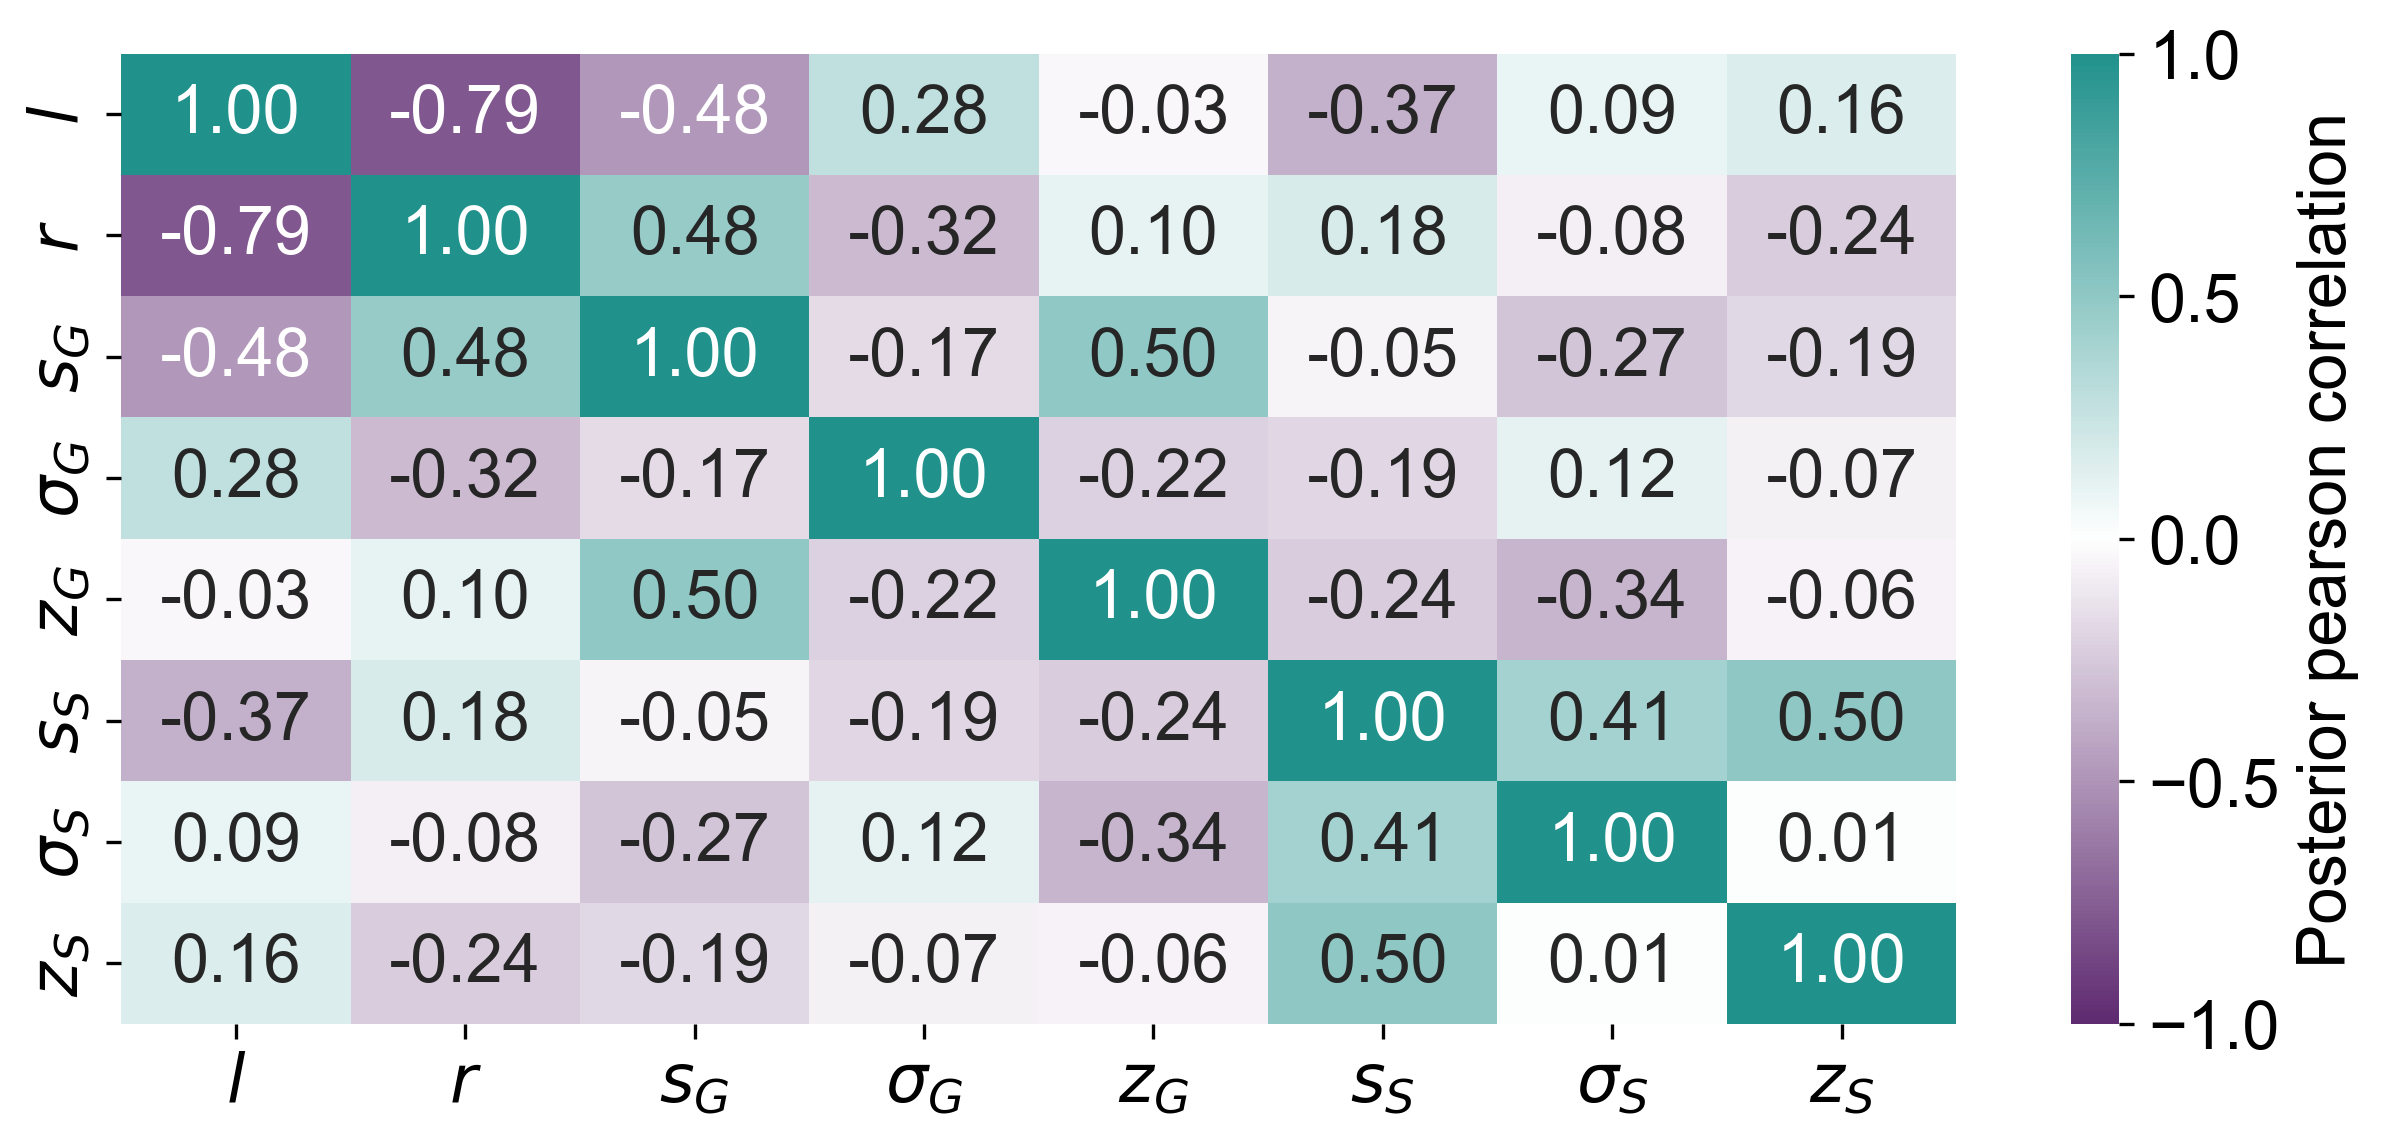

In [27]:
plt.style.use('default')
set_fontsize()

p = history.max_t
df_post, w_post = history.get_distribution(0, p)
params = [c for c in df_post.columns]
df_plot = df_post.copy()
n_samples = 3000 if len(df_plot) > 3000 else len(df_plot)
df_plot = df_plot.sample(n=n_samples, replace=True, weights=w_post, random_state=42)

plt.figure(figsize=(8.43,4.1), dpi=300)

rename_map = {
    "ld": r"$l$",
    "ldr": r"$r$",
    "scaleG": r"$s_G$",
    "noise1G": r"$\sigma_G$",
    "noise2G": r"$z_G$",
    "scaleS": r"$s_S$",
    "noise1S": r"$\sigma_S$",
    "noise2S": r"$z_S$",
}

ordered_params = list(rename_map.keys())
corr = df_plot[params].corr()
corr = corr.loc[ordered_params, ordered_params]
corr.index = [rename_map[c] for c in corr.index]
corr.columns = [rename_map[c] for c in corr.columns]

custom_cmap = mcolors.LinearSegmentedColormap.from_list(
    "blue_maroon", [purple, "white", teal]
)

sns.heatmap(corr, annot=True, fmt=".2f", square=False, cmap=custom_cmap, vmin = -1, vmax = 1,
            cbar_kws={"label": "Posterior pearson correlation", "ticks": [-1, -0.5, 0, 0.5, 1]})
plt.tight_layout()
plt.savefig(f"{plot_path}/param_corr_heatmap.png", dpi=300)
plt.show()

In [28]:
l_values = df_plot['ld']
r_values = df_plot['ldr']

corr_l_r, pval_l_r = pearsonr(l_values, r_values)

print(f"Correlation between l and r: {corr_l_r:.2f}")
print(f"P-value for the correlation: {pval_l_r}")

Correlation between l and r: -0.79
P-value for the correlation: 2.341878055625637e-43


In [29]:
stat_results = []

for pid, df_p in sim_cases.groupby("particle"):
    cases_nl = df_p[df_p["Category"] == "Non-Emergency"]["cases"]
    cases_l  = df_p[df_p["Category"] == "Emergency"]["cases"]

    t_stat, t_p = ttest_ind(cases_l, cases_nl, equal_var=False)
    u_stat, u_p = mannwhitneyu(cases_l, cases_nl, alternative='two-sided')

    stat_results.append({
        "particle": pid,
        "mean_nl": cases_nl.mean(),
        "mean_l": cases_l.mean(),
        "t_stat": t_stat,
        "t_p": t_p,
        "u_stat": u_stat,
        "u_p": u_p,
        "t_sig": t_p < 0.05,
        "u_sig": u_p < 0.05,
    })

stat_df = pd.DataFrame(stat_results)

print("\nParticles with significant lockdown vs non-lockdown difference in cases by Welch's t-test:")
print(stat_df["t_sig"].sum())

print("\nParticles with significant lockdown vs non-lockdown difference in cases by Mann-Whitney U-test:")
print(stat_df["u_sig"].sum())


Particles with significant lockdown vs non-lockdown difference in cases by Welch's t-test:
15

Particles with significant lockdown vs non-lockdown difference in cases by Mann-Whitney U-test:
17


In [30]:
stat_results = []

for pid, df_p in sim_ww.groupby("particle"):
    for loc in ['24h Probe', 'Schmidbartlanger']:
        df_loc = df_p[df_p["Name"] == loc]
        ww_nl = df_loc[df_loc["Category"] == "Non-Emergency"]["ww"]
        ww_l  = df_loc[df_loc["Category"] == "Emergency"]["ww"]

        t_stat, t_p = ttest_ind(ww_l, ww_nl, equal_var=False)
        u_stat, u_p = mannwhitneyu(ww_l, ww_nl, alternative='two-sided')

        stat_results.append({
            "particle": pid,
            "location": loc,
            "mean_nl": ww_nl.mean(),
            "mean_l": ww_l.mean(),
            "t_stat": t_stat,
            "t_p": t_p,
            "u_stat": u_stat,
            "u_p": u_p,
            "t_sig": t_p < 0.05,
            "u_sig": u_p < 0.05,
        })

stat_df = pd.DataFrame(stat_results)

summary = stat_df.groupby("location")["t_sig"].sum()
print("\nParticles with significant lockdown vs non-lockdown difference in ww by Welch's t-test:")
print(summary)    

summary2 = stat_df.groupby("location")["u_sig"].sum()
print("\nParticles with significant lockdown vs non-lockdown difference in ww by Mann-Whitney U-test:")
print(summary2)


Particles with significant lockdown vs non-lockdown difference in ww by Welch's t-test:
location
24h Probe           133
Schmidbartlanger     43
Name: t_sig, dtype: int64

Particles with significant lockdown vs non-lockdown difference in ww by Mann-Whitney U-test:
location
24h Probe           156
Schmidbartlanger     29
Name: u_sig, dtype: int64
